# The AI-free written business case: what must a page carry?

**Week 4, Tuesday, concept notebook 5 of 5, beside chapter 7 of the deck.** Ramesh's shop
returns from notebook 01 with the same invented numbers. His son wrote two versions of the
case for keeping the longer hours: a draft of nine lines and a page of four sentences. This
notebook writes nothing: it counts what the two versions carry, and afterwards it checks
the page you write by hand in chapter 9.

**Who needs the answer.** Ramesh (invented), reading his son's page alone in the evening,
and later today the city head, reading the page each learner writes by hand. A **business
case** says what to do, why, what it costs, what it returns and what could go wrong. It is
one page because the reader has two minutes, and it is written without AI because it shows
your own thinking.

**The questions on the way.** Which opening does Ramesh act on? What do the draft and the
page carry, counted? What goes on the page, in what order? Which words stay off it?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

import re
text = open("../data/C2_W04_D02_kirana_page_STUDENT.txt", encoding="utf-8").read()
draft_text, page_text = text.split("=====")
draft = [l[2:] for l in draft_text.splitlines() if l.startswith("- ")]
page = [l for l in page_text.splitlines() if l.strip() and not l.startswith("VERSION")]
print(text)                                    # both versions in full; every number is invented
check("the draft has nine lines", len(draft) == 9)
check("the page has four sentences", len(page) == 4)

VERSION A: THE DRAFT
- North star (sales a day): Rs 11,900 to Rs 12,600
- Denominator: hours open, 10 to 12
- Sales per hour index: 100 to 88
- Customers a day: 119 to 126
- Sales per customer: Rs 100 in both months
- Rain days: 5 and 2
- Festival days: none and 14
- Helper's extra cost: Rs 170 a day
- Guardrail: sales per customer held
=====
VERSION B: THE PAGE
Keep the longer hours for one more month and count the evening's own sales, because the two extra hours have brought Rs 700 a day while each hour of the day now earns less.
Sales per hour fell from Rs 1,190 in September to Rs 1,050 in October, and sales per customer held at Rs 100.
A festival fortnight fell inside October, so part of the extra Rs 700 a day may be the season.
Keep the hours through November, write the evening's sales in a separate column each day, and decide after thirty days; the helper's two extra hours cost Rs 170 a day, and Ramesh signs.

PASS the draft has nine lines
PASS the page has four sentences


## Which opening does Ramesh act on in two minutes?

**Opening A** is the draft's first three lines; **opening B** is the page's first sentence.

**Predict before you run.** Does a business case need a spreadsheet and ten pages? Which
opening does Ramesh act on?

a) A, since it carries more numbers
b) B, since it states the claim in a sentence
c) Neither, without a chart
d) Both equally

Opening A: North star (sales a day): Rs 11,900 to Rs 12,600 / Denominator: hours open, 10 to 12 / Sales per hour index: 100 to 88
Opening B: Keep the longer hours for one more month and count the evening's own sales, because the two extra hours have brought Rs 700 a day while each hour of the day now earns less.
              the draft  the page
lines                 9         4
numbers              13         6
method words          4         0
PASS the draft carries 13 numbers and the page 6
PASS the page carries no method word


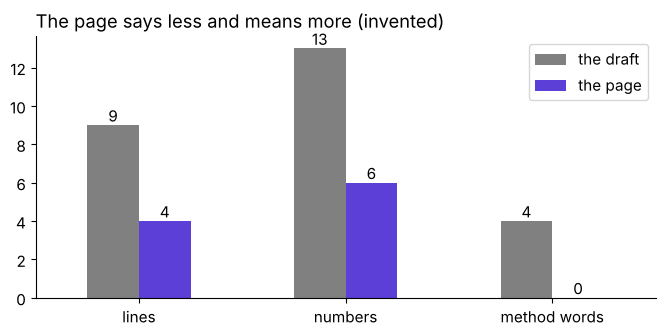

In [2]:
METHOD = ["denominator", "index", "guardrail", "north star"]

def counts(body):
    """Lines, numbers and method words a reader has to get through."""
    lines = [l for l in body.splitlines() if l.strip() and not l.startswith("VERSION")]
    return {"lines": len(lines), "numbers": len(re.findall(r"\d[\d,.]*", body)),
            "method words": sum(word in body.lower() for word in METHOD)}

table = pd.DataFrame({"the draft": counts(draft_text), "the page": counts(page_text)})
print("Opening A:", " / ".join(draft[:3]))
print("Opening B:", page[0])
print(table.to_string())
check("the draft carries 13 numbers and the page 6", table.loc["numbers"].tolist() == [13, 6])
check("the page carries no method word", table.loc["method words", "the page"] == 0)

ax = table.plot.bar(color=["gray", VIOLET], figsize=(8, 3.4), rot=0)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("The page says less and means more (invented)", loc="left")
plt.show()

**What happened.** The answer is b. A sentence has to carry its reasoning where a bullet can
hide it, and opening B says what to do and why before any number. Opening A needs a reader
who knows what a north star, a denominator and an index are. The draft runs to nine lines,
13 numbers and four method words; the page to four sentences, 6 numbers and none.

Amazon's 2017 letter to shareholders, filed 18 April 2018, says: "We don't do PowerPoint
(or any other slide-oriented) presentations at Amazon." The owner writes a six-page memo
and the room reads it in silence at the start of the meeting. The afternoon's page is the
memo form of the morning's slide, cut to one page.

## What goes on the page, in what order?

**Predict before you run.** Where on the page does the caveat sit?

a) First, so nobody misses it
b) Before the action, so the reader meets the doubt before the cost
c) After the action, as a footnote
d) In an attachment

   claim: Keep the longer hours for one more month and count the evening's own sales, because the two extra hours have brought Rs 700 a day while each hour of the day now earns less.
evidence: Sales per hour fell from Rs 1,190 in September to Rs 1,050 in October, and sales per customer held at Rs 100.
  caveat: A festival fortnight fell inside October, so part of the extra Rs 700 a day may be the season.
  action: Keep the hours through November, write the evening's sales in a separate column each day, and decide after thirty days; the helper's two extra hours cost Rs 170 a day, and Ramesh signs.
PASS the claim comes first and gives its reason
PASS the evidence carries a number with what it is divided by
PASS the caveat sits before the action
PASS the action carries its cost and who signs


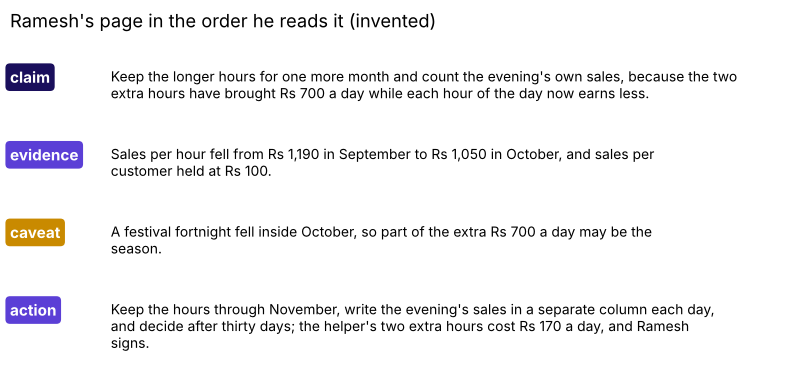

In [3]:
parts = ["claim", "evidence", "caveat", "action"]
for part, sentence in zip(parts, page):
    print(f"{part:>8}: {sentence}")
check("the claim comes first and gives its reason", "because" in page[0])
check("the evidence carries a number with what it is divided by", "per hour" in page[1])
check("the caveat sits before the action", parts.index("caveat") < parts.index("action"))
check("the action carries its cost and who signs", "Rs" in page[3] and "signs" in page[3])

fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (part, sentence) in enumerate(zip(parts, page)):
    y = 0.9 - k * 0.24
    ax.text(0.0, y, part, weight="bold", color="white", va="top",
            bbox=dict(boxstyle="round", fc=[INK, VIOLET, AMBER, VIOLET][k], ec="none"))
    ax.text(0.13, y, textwrap.fill(sentence, 92), va="top", fontsize=10)
ax.axis("off")
ax.set_title("Ramesh's page in the order he reads it (invented)", loc="left")
plt.show()

**What happened.** The answer is b. The page runs claim, evidence, caveat, action, one
sentence each: the reader meets the doubt before the cost, and the action names what to do,
what it costs (Rs 170 a day) and who signs.

## Which words stay off the page?

A method word is one a reader has to decode before the sentence means anything. Each has
plain words that replace it:

| Method word | The plain words that replace it |
|---|---|
| Denominator | divided by |
| Index | compared with the month before |
| Guardrail | a number that must not get worse |
| North star | the one number the team is judged on |

**The plausible wrong answer.** "The draft is the thorough version: it carries every
number, so it should go to Ramesh." The check below is the rule as a function, run on both
versions; the draft fails it where a reader would.

                                       the draft  the page
opens on a claim with its reason           False      True
no method words                            False      True
the action names a cost and who signs      False      True
one page, 250 words or fewer                True      True
four to six sentences                      False      True
words on the page: 108
PASS the page passes every rule
PASS the draft fails the claim and the method words


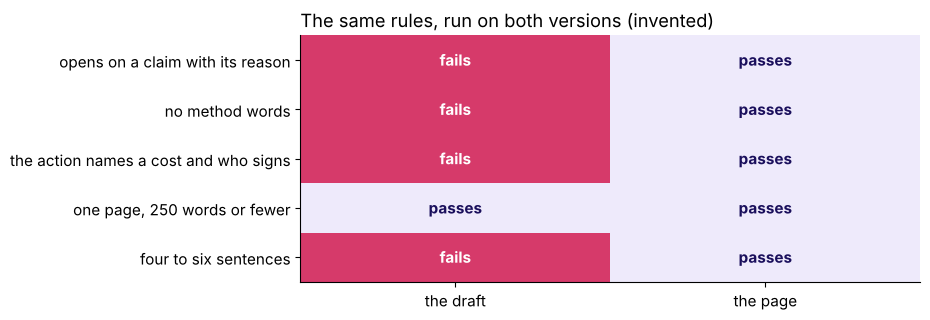

In [4]:
def page_check(text):
    """The AI-free written business case, as checks a reader would make in two minutes."""
    sentences = [s for s in text.splitlines() if s.strip() and not s.startswith("VERSION")]
    words = len(text.split())
    return {"opens on a claim with its reason": "because" in sentences[0] or " so " in sentences[0],
            "no method words": not any(w in text.lower() for w in METHOD),
            "the action names a cost and who signs": "Rs" in sentences[-1] and "signs" in sentences[-1],
            "one page, 250 words or fewer": words <= 250,
            "four to six sentences": 4 <= len(sentences) <= 6}

grid = pd.DataFrame({"the draft": page_check(draft_text), "the page": page_check(page_text)})
print(grid.to_string())
print("words on the page:", sum(len(s.split()) for s in page))
check("the page passes every rule", grid["the page"].all())
check("the draft fails the claim and the method words", not grid.loc["opens on a claim with its reason", "the draft"]
      and not grid.loc["no method words", "the draft"])

fig, ax = plt.subplots(figsize=(8, 3.2))
from matplotlib.colors import ListedColormap
ax.imshow(grid.astype(int).values, cmap=ListedColormap([ROSE, PALE]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(2), grid.columns)
ax.set_yticks(range(len(grid)), grid.index)
for i in range(len(grid)):
    for j in range(2):
        ax.text(j, i, "passes" if grid.iloc[i, j] else "fails", ha="center", va="center",
                color=INK if grid.iloc[i, j] else "white", weight="bold")
ax.set_title("The same rules, run on both versions (invented)", loc="left")
plt.show()

**Why it is wrong.** Thorough is measured by what the reader can act on in two minutes. The
draft opens on a list of figures with no claim, needs four method words decoded, and puts
no cost or signer in its last line; the page carries 108 words and passes every rule.
**The check:** read the first sentence alone: does it say what to do and why? **The fix:**
the four parts as four sentences, in plain words.

Named last: the AI-free written business case is the slide's four parts as four sentences
on one page, read in two minutes by someone who was not in the room, written by hand in
your own words.

**Your turn, after chapter 9.** Type the page you wrote by hand for the city head into
`my_page`, one sentence a line, and run the same rules on it. The rules check the shape;
your trainer reads the argument. Type the lines into the empty cell below and run them:

```python
my_page = """
___
""".strip()
mine = page_check(my_page)
print(pd.Series(mine).to_string())
check("my page opens on its claim", mine["opens on a claim with its reason"])
check("my page carries no method words", mine["no method words"])
```

## Which rules does the chapter leave?

1. The first sentence is the claim, with what to do and why.
2. The second carries one number, what it is divided by and its window.
3. The caveat comes before the action, so the reader meets the doubt first.
4. The action names what to do, its cost in rupees and weeks, and who signs.

**In the interview.** [S] Present a recommendation to a non-technical stakeholder in two
minutes: the page, spoken.

**Where it is used next.** Chapter 9 is the page to the city head, written by hand in 35
minutes with laptops closed, so it has no notebook; this notebook's `page_check` is the
check you run on it afterwards.